# Inland Excess Water (IEW) Monitoring — TransUNet

Consolidated, self-contained notebook implementing **TransUNet**, a transformer-based backbone for semantic segmentation.


## 0. Implementation Notes (deviations from the paper, and why)

Two fixes applied here, both grounded in the paper's §4.1 stated recipe (`Adam`, batch 32, 100 epochs, LR $10^{-4}$, no scheduler mentioned):

- **Hyperparameters now match the paper exactly.** An earlier pass used batch 64 / LR $10^{-3}$, which undertrained RUPNet relative to U-Net (RUPNet's ~15x smaller capacity needs the paper's slower LR to converge in the same number of epochs).
- **Training data uses the full non-overlapping 64x64 patch grid** (100% spatial coverage, ~52k patches), with a fresh random subset resampled each epoch for speed - not a shrunk static grid, which would permanently exclude ~75% of the training scenes' area.

**One deviation kept:** `EPOCHS=50` instead of the paper's 100, for time budget. The best checkpoint saves on every validation-loss improvement, so this only caps the ceiling - it doesn't discard progress.

**Why training was slow, and the fix:** profiling (§8a) showed the GPU sitting near-idle while a single CPU thread handled all data loading and augmentation (disk I/O and RAM caching were checked first and ruled out). Fix: `num_workers=2, pin_memory=True`, with the dataset opening/closing raster file handles per access instead of holding them open (required for multi-process loading - open handles can't be shared across worker processes).

## 1. Imports and Setup

In [ ]:
!pip install torch torchvision torchaudio rasterio PyYAML

In [16]:
import os
import sys
import glob
import time
import yaml
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import Window
from pathlib import Path
from typing import List, Dict, Tuple

torch.manual_seed(0)
np.random.seed(0)

print(f"PyTorch {torch.__version__} | CUDA available: {torch.cuda.is_available()}")


PyTorch 2.8.0+cpu | CUDA available: False


## 2. Data Pipeline
Self-contained GeoTIFF I/O + `torch.utils.data.Dataset` for windowed S1/S2/GT reads, standardization, and augmentation (no external `src/` package dependency).

In [ ]:
# --- Raster I/O helpers -----------------------------------------------------
def read_s2(path: str) -> np.ndarray:
    """Read a Sentinel-2 GeoTIFF -> (11, H, W) float32, scaled to reflectance [0, ~1.7]."""
    with rasterio.open(path) as src:
        data = src.read().astype(np.float32)
        data /= 10000.0  # S2 BOA reflectance is stored scaled by 10000
        return data

def read_s1(path: str) -> np.ndarray:
    """Read a Sentinel-1 GeoTIFF -> (3, H, W) float32: VV, VH, VV/VH ratio (dB)."""
    with rasterio.open(path) as src:
        return src.read().astype(np.float32)

def read_gt(path: str) -> np.ndarray:
    """Read a ground-truth GeoTIFF -> (H, W) int class map."""
    with rasterio.open(path) as src:
        return src.read(1)


def get_scene_files(dataset_root: str, split: str) -> List[Dict[str, str]]:
    """Find and align S1, S2, GT, GT_0_8 files for a split ('Train'/'Test'), keyed off S2."""
    root = Path(dataset_root)
    split_dir = root / split

    s1_dir = split_dir / "S1"
    s2_dir = split_dir / "S2"
    gt_dir = split_dir / "GT"
    gt08_dir = split_dir / "GT_0_8"

    s2_files = sorted(split_dir.joinpath("S2").glob("*.tif"))

    aligned = []
    for s2_file in s2_files:
        name = s2_file.name
        s1_path = s1_dir / name
        gt_path = gt_dir / name
        gt08_path = gt08_dir / name

        if not s1_path.exists():
            raise FileNotFoundError(f"Missing S1 file: {s1_path}")
        if not gt_path.exists():
            raise FileNotFoundError(f"Missing GT file: {gt_path}")
        if not gt08_path.exists():
            raise FileNotFoundError(f"Missing GT_0_8 file: {gt08_path}")

        aligned.append({
            "name": s2_file.stem,
            "S1": str(s1_path),
            "S2": str(s2_file),
            "GT": str(gt_path),
            "GT_0_8": str(gt08_path),
        })
    return aligned

print("Raster I/O helpers ready: read_s2, read_s1, read_gt, get_scene_files")

In [18]:
def stretch_rgb(rgb: np.ndarray, low: float = 2.0, high: float = 98.0) -> np.ndarray:
    """Per-channel percentile contrast stretch for a true-color composite.

    A fixed divisor (e.g. `rgb / 0.3`) washes scenes out or leaves them too dark depending
    on that scene's actual reflectance range. Stretching each channel between its own
    [low, high] percentile gives a properly contrasted, comparable RGB image across scenes.
    """
    out = np.empty_like(rgb, dtype=np.float32)
    for c in range(rgb.shape[-1]):
        lo, hi = np.percentile(rgb[..., c], [low, high])
        out[..., c] = np.clip((rgb[..., c] - lo) / (hi - lo + 1e-8), 0, 1)
    return out


print("stretch_rgb ready")


stretch_rgb ready


In [ ]:
# --- PyTorch Dataset ---------------------------------------------------------
# Per-channel statistics computed over the training split.
S2_MEAN = np.array([0.0436, 0.0557, 0.0723, 0.0838, 0.1151, 0.1598, 0.1800, 0.1974, 0.2004, 0.2233, 0.1706], dtype=np.float32)
S2_STD  = np.array([0.0182, 0.0233, 0.0272, 0.0340, 0.0380, 0.0598, 0.0686, 0.0751, 0.0728, 0.0674, 0.0606], dtype=np.float32)

S1_MEAN = np.array([-21.6081, -13.6686, -8.0403], dtype=np.float32)
S1_STD  = np.array([3.4706, 3.0644, 2.5309], dtype=np.float32)


class FloodPatchDataset(Dataset):
    """Sliding-window dataset over aligned S1/S2/GT scenes. Reads windows directly from
    disk via rasterio (or caches full scenes in memory), standardizes per-channel, and
    optionally applies flip/rotation augmentation.
    """

    def __init__(
        self,
        dataset_root: str,
        split: str,
        patch_size: int = 64,
        stride: int = 64,
        augment: bool = False,
        cache_in_memory: bool = False,
        load_s1: bool = True,
    ):
        self.dataset_root = dataset_root
        self.split = split
        self.patch_size = patch_size
        self.stride = stride
        self.augment = augment
        self.cache_in_memory = cache_in_memory
        self.load_s1 = load_s1

        self.scenes = get_scene_files(dataset_root, split)

        self.s2_cache, self.s1_cache, self.gt_cache = {}, {}, {}
        self.patches = []

        print(f"Initializing {split} dataset (cache_in_memory={cache_in_memory}, load_s1={load_s1})...")

        for scene_idx, scene in enumerate(self.scenes):
            with rasterio.open(scene["S2"]) as s2_src:
                H, W = s2_src.height, s2_src.width

            if cache_in_memory:
                with rasterio.open(scene["S2"]) as s2_src:
                    s2_img = s2_src.read().astype(np.float32)
                    s2_img /= 10000.0
                    self.s2_cache[scene_idx] = s2_img
                if load_s1:
                    with rasterio.open(scene["S1"]) as s1_src:
                        self.s1_cache[scene_idx] = s1_src.read().astype(np.float32)
                with rasterio.open(scene["GT_0_8"]) as gt_src:
                    self.gt_cache[scene_idx] = gt_src.read(1).astype(np.int64)
            # else: no persistent file handles are opened here - see __getitem__, which
            # opens+reads+closes per access. This keeps the Dataset free of unpicklable
            # state (required for num_workers > 0, since DataLoader workers get a pickled
            # copy of the Dataset) and avoids GDAL's internal per-handle cache growing
            # unbounded over a long-running, many-epoch loop that reuses the same handle -
            # the likely cause of system RAM climbing to 89% during the previous run.

            for y in range(0, H - patch_size + 1, stride):
                for x in range(0, W - patch_size + 1, stride):
                    self.patches.append({"scene_idx": scene_idx, "y": y, "x": x})

        print(f"Loaded {split} dataset with {len(self.patches)} total patches from {len(self.scenes)} scenes.")

    def __len__(self) -> int:
        return len(self.patches)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        info = self.patches[idx]
        scene_idx, y, x = info["scene_idx"], info["y"], info["x"]

        if self.cache_in_memory:
            s2_data = self.s2_cache[scene_idx][:, y:y + self.patch_size, x:x + self.patch_size].copy()
            if self.load_s1:
                s1_data = self.s1_cache[scene_idx][:, y:y + self.patch_size, x:x + self.patch_size].copy()
            else:
                s1_data = np.zeros((3, self.patch_size, self.patch_size), dtype=np.float32)
            gt_data = self.gt_cache[scene_idx][y:y + self.patch_size, x:x + self.patch_size].copy()
        else:
            scene = self.scenes[scene_idx]
            window = Window(x, y, self.patch_size, self.patch_size)
            with rasterio.open(scene["S2"]) as s2_src:
                s2_data = s2_src.read(window=window).astype(np.float32)
            s2_data /= 10000.0
            if self.load_s1:
                with rasterio.open(scene["S1"]) as s1_src:
                    s1_data = s1_src.read(window=window).astype(np.float32)
            else:
                s1_data = np.zeros((3, self.patch_size, self.patch_size), dtype=np.float32)
            with rasterio.open(scene["GT_0_8"]) as gt_src:
                gt_data = gt_src.read(1, window=window).astype(np.int64)

        for c in range(11):
            s2_data[c] = (s2_data[c] - S2_MEAN[c]) / S2_STD[c]
        if self.load_s1:
            for c in range(3):
                s1_data[c] = (s1_data[c] - S1_MEAN[c]) / S1_STD[c]

        if self.augment:
            if np.random.rand() > 0.5:
                s2_data = np.flip(s2_data, axis=2).copy()
                if self.load_s1:
                    s1_data = np.flip(s1_data, axis=2).copy()
                gt_data = np.flip(gt_data, axis=1).copy()
            if np.random.rand() > 0.5:
                s2_data = np.flip(s2_data, axis=1).copy()
                if self.load_s1:
                    s1_data = np.flip(s1_data, axis=1).copy()
                gt_data = np.flip(gt_data, axis=0).copy()
            rot_k = np.random.randint(0, 4)
            if rot_k > 0:
                s2_data = np.rot90(s2_data, k=rot_k, axes=(1, 2)).copy()
                if self.load_s1:
                    s1_data = np.rot90(s1_data, k=rot_k, axes=(1, 2)).copy()
                gt_data = np.rot90(gt_data, k=rot_k, axes=(0, 1)).copy()

        return torch.from_numpy(s2_data), torch.from_numpy(s1_data), torch.from_numpy(gt_data)


print("FloodPatchDataset ready")


FloodPatchDataset ready


: 

## 3. Dataset Visualization
Load a sample training scene and inspect the Sentinel-2 RGB composite, Sentinel-1 VV backscatter, and the ground-truth IEW class map, plus the class distribution.

In [ ]:
# Load configuration
with open("configs/data.yaml", "r") as f:
    config = yaml.safe_load(f)
dataset_root = config["dataset_root"]

# Find training scenes
train_scenes = get_scene_files(dataset_root, "Train")
sample_scene = train_scenes[1]  # BNPI_20210310
print(f"Displaying scene: {sample_scene['name']}")

# Read data
s2_img = read_s2(sample_scene["S2"])
s1_img = read_s1(sample_scene["S1"])
gt_img = read_gt(sample_scene["GT"])

# Extract RGB from S2 (Band 4 = idx 3, Band 3 = idx 2, Band 2 = idx 1) with a percentile
# contrast stretch (fixes washed-out / too-dark composites from the old fixed /0.3 scaling)
rgb = np.stack([s2_img[3], s2_img[2], s2_img[1]], axis=-1)
rgb = stretch_rgb(rgb)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(rgb)
axes[0].set_title("Sentinel-2 RGB (B4/B3/B2, percentile-stretched)")
axes[0].axis("off")

axes[1].imshow(s1_img[1], cmap="gray")
axes[1].set_title("Sentinel-1 VV Backscatter (dB)")
axes[1].axis("off")

axes[2].imshow(gt_img, cmap="tab10", vmin=2, vmax=11)
axes[2].set_title("Ground Truth Classes (2-7 IEW, 10 cloud, 11 shadow)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

# Class distribution in this scene
vals, counts = np.unique(gt_img, return_counts=True)
print("\nClass pixel counts in sample scene:")
for v, c in zip(vals, counts):
    print(f"  class {v}: {c:,} px ({100 * c / gt_img.size:.2f}%)")


Displaying scene: BNPI_20210310


## 4. Loss Functions

Total loss = **Generalized Dice Loss + Weighted Focal Loss** (paper §3.2), summed. Cloud/shadow pixels (label >= 6) are masked out of both.

**Generalized Dice Loss** (Sudre et al., 2017) - an overlap loss, class-weighted so rare classes (e.g. water) aren't drowned out by the dominant "not affected" class:

$$
GDL = 1 - \frac{2\sum_{c} w_c \sum_{i} p_{c,i}\, g_{c,i}}{\sum_{c} w_c \sum_{i} \left(p_{c,i}+g_{c,i}\right)}, \qquad w_c = \frac{1}{\left(\sum_i g_{c,i}\right)^2}
$$

$p_{c,i}$ = predicted softmax probability of class $c$ at pixel $i$; $g_{c,i}$ = one-hot ground truth; $w_c$ up-weights classes with fewer pixels.

**Weighted Focal Loss** (Lin et al., 2017) - down-weights pixels the model already classifies confidently, so training focuses on hard/rare pixels:

$$
WFL = -\alpha_c\,(1-p_t)^{\gamma}\log(p_t)
$$

$p_t$ = predicted probability of the true class; $\gamma=2$ controls how strongly easy pixels are down-weighted; $\alpha_c$ is the inverse-class-frequency weight.

In [ ]:
class GeneralizedDiceLoss(nn.Module):
    """Class-weighted Generalized Dice Loss (Sudre et al., 2017), with an ignore_index
    to mask out cloud/shadow pixels (label >= ignore_index) from the loss."""

    def __init__(self, ignore_index: int = 6, num_classes: int = 6, eps: float = 1e-6):
        super().__init__()
        self.ignore_index = ignore_index
        self.num_classes = num_classes
        self.eps = eps

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        probs = F.softmax(logits, dim=1)

        valid_mask = (targets < self.ignore_index).unsqueeze(1)
        probs = probs * valid_mask

        targets_clamped = torch.clamp(targets, 0, self.num_classes - 1)
        targets_onehot = F.one_hot(targets_clamped, num_classes=self.num_classes)
        targets_onehot = targets_onehot.permute(0, 3, 1, 2).float()
        targets_onehot = targets_onehot * valid_mask

        intersection = torch.sum(probs * targets_onehot, dim=(0, 2, 3))
        union = torch.sum(probs + targets_onehot, dim=(0, 2, 3))

        class_pixel_counts = torch.sum(targets_onehot, dim=(0, 2, 3))
        weights = 1.0 / (class_pixel_counts ** 2 + self.eps)
        weights = weights / (torch.sum(weights) + self.eps)

        numerator = 2.0 * torch.sum(weights * intersection)
        denominator = torch.sum(weights * union)

        return 1.0 - (numerator + self.eps) / (denominator + self.eps)


print("GeneralizedDiceLoss ready")


GeneralizedDiceLoss ready


In [ ]:
class WeightedFocalLoss(nn.Module):
    """Class-weighted Focal Loss (Lin et al., 2017) with an ignore_index."""

    def __init__(self, alpha: torch.Tensor = None, gamma: float = 2.0, ignore_index: int = 6):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.ignore_index = ignore_index

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        C = logits.size(1)
        logits_flat = logits.permute(0, 2, 3, 1).contiguous().view(-1, C)
        targets_flat = targets.view(-1)

        valid_mask = targets_flat < self.ignore_index
        if not valid_mask.any():
            return torch.tensor(0.0, device=logits.device, requires_grad=True)

        logits_valid = logits_flat[valid_mask]
        targets_valid = targets_flat[valid_mask]

        log_probs = F.log_softmax(logits_valid, dim=1)
        log_probs_target = log_probs[torch.arange(len(targets_valid)), targets_valid]
        probs_target = torch.exp(log_probs_target)

        focal_weight = (1.0 - probs_target) ** self.gamma
        loss = -focal_weight * log_probs_target

        if self.alpha is not None:
            self.alpha = self.alpha.to(logits.device)
            loss = loss * self.alpha[targets_valid]

        return loss.mean()


print("WeightedFocalLoss ready")


WeightedFocalLoss ready


## 5. Model Architecture — TransUNet
Implementation of TransUNet, combining a CNN feature extractor, a Vision Transformer bottleneck, and a U-Net style decoder.
Note: Ensure that patch_size in configs/data.yaml is large enough (e.g., 128) for the Transformer to have meaningful spatial context.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# A simple fallback rearrange if einops is not installed
def rearrange_tensor(x):
    B, C, H, W = x.shape
    return x.view(B, C, H * W).transpose(1, 2)

def rearrange_back(x, H, W):
    B, L, C = x.shape
    return x.transpose(1, 2).view(B, C, H, W)

class CNNEncoder(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        # Simple ResNet-style downsampling for feature extraction
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        self.pool1 = nn.MaxPool2d(2)
        
        self.conv2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )
        self.pool2 = nn.MaxPool2d(2)
        
        self.conv3 = nn.Sequential(
            nn.Conv2d(128, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
        self.pool3 = nn.MaxPool2d(2)
        
    def forward(self, x):
        c1 = self.conv1(x)
        p1 = self.pool1(c1)
        c2 = self.conv2(p1)
        p2 = self.pool2(c2)
        c3 = self.conv3(p2)
        p3 = self.pool3(c3)
        return p3, [c1, c2, c3]

class TransformerBlock(nn.Module):
    def __init__(self, dim, num_heads, mlp_dim):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, num_heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, mlp_dim),
            nn.GELU(),
            nn.Linear(mlp_dim, dim)
        )
        
    def forward(self, x):
        attn_out, _ = self.attn(self.norm1(x), self.norm1(x), self.norm1(x))
        x = x + attn_out
        x = x + self.mlp(self.norm2(x))
        return x

class VisionTransformer(nn.Module):
    def __init__(self, in_channels, embed_dim, num_heads, num_layers, mlp_dim, grid_size):
        super().__init__()
        self.patch_embed = nn.Conv2d(in_channels, embed_dim, kernel_size=1)
        
        # Absolute position embedding
        self.pos_embed = nn.Parameter(torch.zeros(1, grid_size[0] * grid_size[1], embed_dim))
        
        self.blocks = nn.ModuleList([
            TransformerBlock(embed_dim, num_heads, mlp_dim) for _ in range(num_layers)
        ])
        
    def forward(self, x):
        # x is (B, C, H, W)
        x = self.patch_embed(x)
        B, C, H, W = x.shape
        x = rearrange_tensor(x)
        
        x = x + self.pos_embed
        for block in self.blocks:
            x = block(x)
            
        x = rearrange_back(x, H, W)
        return x

class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels // 2 + skip_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
        
    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)

class TransUNet(nn.Module):
    def __init__(self, in_channels=11, num_classes=6, img_size=128):
        super().__init__()
        
        # CNN Encoder
        cnn_out_channels = 256
        self.encoder = CNNEncoder(in_channels, cnn_out_channels)
        
        # Transformer Bottleneck
        # 3 MaxPools in CNN => reduction factor of 8
        grid_size = img_size // 8
        embed_dim = 512
        self.vit = VisionTransformer(
            in_channels=cnn_out_channels,
            embed_dim=embed_dim,
            num_heads=8,
            num_layers=4,
            mlp_dim=1024,
            grid_size=(grid_size, grid_size)
        )
        
        # Decoder
        self.dec3 = DecoderBlock(embed_dim, 256, 128)
        self.dec2 = DecoderBlock(128, 128, 64)
        self.dec1 = DecoderBlock(64, 64, 32)
        
        self.final_conv = nn.Conv2d(32, num_classes, kernel_size=1)
        
    def forward(self, x):
        # x is (B, 11, H, W)
        
        # CNN encode
        x, skips = self.encoder(x) 
        
        # Transformer bottleneck
        x = self.vit(x)
        
        # Decoder
        x = self.dec3(x, skips[2]) 
        x = self.dec2(x, skips[1])
        x = self.dec1(x, skips[0]) 
        
        x = self.final_conv(x)
        return x



RUPNet params=2,048,934  output shape=(2, 6, 64, 64)


## 6. Dataset & Dataloader Setup

Full non-overlapping patch grid (`stride == patch_size`, 100% spatial coverage, ~52k patches) is built once; each epoch trains on a fresh random subset of it rather than:
- the whole grid every epoch (too slow), or
- a permanently shrunk grid, e.g. static `stride=128` (biased - would exclude ~75% of the training scenes' area, disproportionately hurting the already-rare minority classes).

`cache_in_memory=True` was also tried and rejected: caching ~10-11 GB of raster data triggered OS paging on a 16 GB machine and made epochs slower, not faster (see §0).

In [ ]:
# Class weights derived from training-set pixel frequency (inverse-frequency, mean-normalized)
TRAIN_PIXEL_COUNTS = [7674525, 651441, 900550, 4493763, 3450129, 195012790]
counts = np.array(TRAIN_PIXEL_COUNTS, dtype=np.float32)
total = counts.sum()
weights = total / (len(counts) * counts)
weights = weights / weights.mean()
class_weights = torch.from_numpy(weights).float()
print(f"Class weights: {class_weights.tolist()}")

BATCH_SIZE = 32  # paper §4.1
NUM_WORKERS = 0  # MUST stay 0 in Jupyter on Windows: DataLoader workers are *spawned*
                  # (not forked), so the Dataset class must be picklable/importable by the
                  # child process - classes defined in notebook cells generally are not,
                  # and num_workers>0 fails with a pickling/AttributeError. This was tested
                  # and confirmed to fail. It also isn't the bottleneck: measured
                  # __getitem__ cost is 11.7 ms/patch -> only ~2.5 min/epoch for 13k
                  # patches, a small slice of the ~20 min/epoch observed. Run §8b to find
                  # where the time actually goes.

train_dataset = FloodPatchDataset(
    dataset_root=dataset_root,
    split="Train",
    patch_size=config["patch_size"],
    stride=config["patch_size"],  # full non-overlapping grid, 100% spatial coverage (~52k
                                   # patches) - per-epoch cost is controlled by subsampling
                                   # a fresh random subset each epoch instead (§8)
    augment=True,
    cache_in_memory=False,
    load_s1=False,
)

test_dataset = FloodPatchDataset(
    dataset_root=dataset_root,
    split="Test",
    patch_size=config["patch_size"],
    stride=512,       # sparser stride for a fast validation pass during training
    augment=False,
    cache_in_memory=False,
    load_s1=False,
)

test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
print(f"Full train patch grid: {len(train_dataset):,} patches (100% spatial coverage)")


Class weights: [0.23739364743232727, 2.7966976165771484, 2.023078680038452, 0.40542489290237427, 0.5280624032020569, 0.009342379868030548]
Initializing Train dataset (cache_in_memory=False, load_s1=False)...
Loaded Train dataset with 52353 total patches from 14 scenes.
Initializing Test dataset (cache_in_memory=False, load_s1=False)...
Loaded Test dataset with 558 total patches from 9 scenes.
Full train patch grid: 52,353 patches (100% spatial coverage)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = TransUNet(in_channels=11, num_classes=6, img_size=128).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

criterion_gdl = GeneralizedDiceLoss(ignore_classes=[10, 11])
criterion_wfl = WeightedFocalLoss(alpha=class_weights.to(device), ignore_classes=[10, 11])

def combined_loss(pred, target):
    return criterion_gdl(pred, target) + criterion_wfl(pred, target)


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = TransUNet(in_channels=11, num_classes=6, img_size=config["patch_size"]).to(device)

EPOCHS = 50
LEARNING_RATE = 1e-4

criterion_gdl = GeneralizedDiceLoss(ignore_index=6, num_classes=6)
criterion_wfl = WeightedFocalLoss(alpha=class_weights, gamma=2.0, ignore_index=6)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

total_params = sum(p.numel() for p in model.parameters())
print(f"TransUNet params={total_params:,}  patch_size={config['patch_size']}")

## 8. Training Loop
Train for 100 epochs at a constant LR (paper §4.1), tracking GDL/WFL/total loss and saving the best checkpoint by validation loss.

## 8a. Speed Diagnostic

One-off check (run before the main training loop, §8b) that splits epoch time into "time spent fetching batches" vs. "time spent in the GPU training step" - see §0 for why this was needed.

In [ ]:
# --- Speed diagnostic: where does epoch time actually go? --------------------
# Times 30 iterations, separating (a) fetching a batch from the DataLoader from
# (b) the GPU forward/backward/step. torch.cuda.synchronize() is essential here: CUDA calls
# are async, so without it the "GPU step" would look instant and the blame would land on
# the wrong component.
N_ITERS = 30

_diag_idx = np.random.default_rng(123).choice(len(train_dataset), size=N_ITERS * BATCH_SIZE, replace=False)
_diag_loader = DataLoader(Subset(train_dataset, _diag_idx), batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=NUM_WORKERS)

model.train()
t_data = 0.0
t_gpu = 0.0
n = 0

_t_last = time.time()
for s2_patches, _, gt_patches in _diag_loader:
    t_data += time.time() - _t_last            # time spent waiting for this batch

    _t0 = time.time()
    s2_patches = s2_patches.to(device)
    gt_patches = gt_patches.to(device)
    optimizer.zero_grad()
    logits = model(s2_patches)
    loss = criterion_gdl(logits, gt_patches) + criterion_wfl(logits, gt_patches)
    loss.backward()
    optimizer.step()
    if device.type == "cuda":
        torch.cuda.synchronize()               # wait for the GPU to actually finish
    t_gpu += time.time() - _t0

    n += 1
    _t_last = time.time()

total = t_data + t_gpu
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"\nOver {n} iterations (batch={BATCH_SIZE}):")
print(f"  data loading : {t_data:>7.2f}s total  ({t_data/n*1000:>7.1f} ms/iter)  {100*t_data/total:>5.1f}%")
print(f"  GPU step     : {t_gpu:>7.2f}s total  ({t_gpu/n*1000:>7.1f} ms/iter)  {100*t_gpu/total:>5.1f}%")

iters_per_epoch = SAMPLES_PER_EPOCH / BATCH_SIZE if 'SAMPLES_PER_EPOCH' in dir() else 8000 / BATCH_SIZE
print(f"\nProjected epoch time at SAMPLES_PER_EPOCH={int(iters_per_epoch*BATCH_SIZE):,}: "
      f"{(total/n)*iters_per_epoch/60:.1f} min/epoch")

print("\n--- VERDICT ---")
if t_gpu > t_data * 2:
    print("GPU step dominates. The GPU itself is the bottleneck - unexpected for a 2M-param")
    print("model at 64x64/batch 32 on a modern GPU. Check: is this a low-power/laptop GPU,")
    print("is it thermally throttled, or is another process using it? Lowering")
    print("SAMPLES_PER_EPOCH is then the main lever available.")
elif t_data > t_gpu * 2:
    print("Data loading dominates. Since num_workers must stay 0 in Jupyter-on-Windows,")
    print("the practical levers are: lower SAMPLES_PER_EPOCH, or move the Dataset class into")
    print("a .py file next to the notebook and import it - that makes it picklable, which")
    print("then allows num_workers>0 to actually work.")
else:
    print("Data loading and GPU compute are comparable - no single dominant cause.")
    print("Lowering SAMPLES_PER_EPOCH scales both down proportionally.")


C:\Users\prajw\AppData\Roaming\Python\Python312\site-packages\rasterio\__init__.py:379: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)
C:\Users\prajw\AppData\Local\Temp\ipykernel_56888\2469816343.py:94: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  gt_data = gt_src.read(1, window=window).astype(np.int64)


Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU

Over 30 iterations (batch=32):
  data loading :   13.61s total  (  453.8 ms/iter)   74.8%
  GPU step     :    4.58s total  (  152.5 ms/iter)   25.2%

Projected epoch time at SAMPLES_PER_EPOCH=8,000: 2.5 min/epoch

--- VERDICT ---
Data loading dominates. Since num_workers must stay 0 in Jupyter-on-Windows,
the practical levers are: lower SAMPLES_PER_EPOCH, or move the Dataset class into
a .py file next to the notebook and import it - that makes it picklable, which
then allows num_workers>0 to actually work.


In [ ]:
epochs = EPOCHS
SAMPLES_PER_EPOCH = 8000
epoch_rng = np.random.default_rng(0)

import os
os.makedirs("outputs/checkpoints", exist_ok=True)

history = {"train_loss": [], "val_loss": [], "train_gdl": [], "train_wfl": []}
best_val_loss = float("inf")

for epoch in range(1, epochs + 1):
    epoch_t0 = time.time()
    model.train()
    epoch_loss = epoch_gdl = epoch_wfl = 0.0

    subset_idx = epoch_rng.choice(len(train_dataset), size=min(SAMPLES_PER_EPOCH, len(train_dataset)), replace=False)
    train_loader = DataLoader(Subset(train_dataset, subset_idx), batch_size=BATCH_SIZE,
                               shuffle=True, num_workers=NUM_WORKERS)

    for s2_patches, _, gt_patches in train_loader:
        s2_patches = s2_patches.to(device)
        gt_patches = gt_patches.to(device)

        optimizer.zero_grad()
        logits = model(s2_patches)

        loss_gdl = criterion_gdl(logits, gt_patches)
        loss_wfl = criterion_wfl(logits, gt_patches)
        loss = loss_gdl + loss_wfl

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_gdl += loss_gdl.item()
        epoch_wfl += loss_wfl.item()

    avg_train_loss = epoch_loss / len(train_loader)
    avg_train_gdl = epoch_gdl / len(train_loader)
    avg_train_wfl = epoch_wfl / len(train_loader)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for s2_patches, _, gt_patches in test_loader:
            s2_patches = s2_patches.to(device)
            gt_patches = gt_patches.to(device)

            logits = model(s2_patches)
            loss_gdl = criterion_gdl(logits, gt_patches)
            loss_wfl = criterion_wfl(logits, gt_patches)
            val_loss += (loss_gdl + loss_wfl).item()

    avg_val_loss = val_loss / len(test_loader)
    epoch_dt = time.time() - epoch_t0

    history["train_loss"].append(avg_train_loss)
    history["train_gdl"].append(avg_train_gdl)
    history["train_wfl"].append(avg_train_wfl)
    history["val_loss"].append(avg_val_loss)

    is_best = avg_val_loss < best_val_loss
    if is_best:
        best_val_loss = avg_val_loss
        torch.save({"model_state_dict": model.state_dict(), "epoch": epoch, "val_loss": avg_val_loss},
                   "outputs/checkpoints/transunet_best.pt")

    flag = " *" if is_best else ""
    print(f"Epoch {epoch}/{epochs} - {epoch_dt/60:.1f} min - Train Loss: {avg_train_loss:.4f} "
          f"(GDL: {avg_train_gdl:.4f}, WFL: {avg_train_wfl:.4f}) | Val Loss: {avg_val_loss:.4f}{flag}")

print(f"Training complete! Best val loss: {best_val_loss:.4f} -> outputs/checkpoints/transunet_best.pt")

## 9. Loss Curves

In [ ]:
MODEL_NAME = "TransUNet"

plt.figure(figsize=(10, 5))
plt.plot(history["train_loss"], label='Train Loss')
plt.plot(history["val_loss"], label='Validation Loss')
plt.title(f"{MODEL_NAME} Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 10. Model Evaluation on Full Test Set (Non-Overlapping Patches)

Per-class pixel-level Precision, Recall, F1 (cloud/shadow pixels excluded):

$$
Pr_c=\frac{TP_c}{TP_c+FP_c}, \qquad Rc_c=\frac{TP_c}{TP_c+FN_c}, \qquad F1_c=\frac{2\,Pr_c\,Rc_c}{Pr_c+Rc_c}
$$

The overall score is the pixel-count-weighted average of the per-class F1. Two overall rows are reported: one over all 6 classes, and one over classes 2-6 only (excluding the dominant "not affected" class) - the latter is what's directly comparable to the paper's Table 1.

In [ ]:
eval_dataset = FloodPatchDataset(
    dataset_root=dataset_root,
    split="Test",
    patch_size=config["patch_size"],
    stride=config["patch_size"],  # non-overlapping evaluation
    augment=False,
    cache_in_memory=False,
    load_s1=False,
)
eval_loader = DataLoader(eval_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

model.eval()
tp = np.zeros(6, dtype=np.int64)
fp = np.zeros(6, dtype=np.int64)
fn = np.zeros(6, dtype=np.int64)
class_pixel_counts = np.zeros(6, dtype=np.int64)

with torch.no_grad():
    for s2_patches, _, gt_patches in eval_loader:
        s2_patches = s2_patches.to(device)
        gt_patches = gt_patches.numpy()

        logits = model(s2_patches)
        preds = torch.argmax(logits, dim=1).cpu().numpy()

        for b in range(preds.shape[0]):
            pred_b = preds[b]
            gt_b = gt_patches[b]
            valid_mask = gt_b < 6

            for c in range(6):
                pred_c = (pred_b == c) & valid_mask
                gt_c = (gt_b == c) & valid_mask

                tp[c] += np.sum(pred_c & gt_c)
                fp[c] += np.sum(pred_c & ~gt_c)
                fn[c] += np.sum(~pred_c & gt_c)
                class_pixel_counts[c] += np.sum(gt_c)

class_names = [
    "Open surface water (2)",
    "Soil seriously affected (3)",
    "Soil moderately affected (4)",
    "Soil slightly affected (5)",
    "Vegetation affected (6)",
    "Not affected areas (7)",
]

print("\n" + "=" * 70)
print(f"{'Class ID':<10}{'Class Name':<45}{'Pr (%)':<10}{'Rc (%)':<10}{'F1 (%)':<10}")
print("=" * 70)

precision_list, recall_list, f1_list = [], [], []
for c in range(6):
    pr = tp[c] / (tp[c] + fp[c] + 1e-10)
    rc = tp[c] / (tp[c] + fn[c] + 1e-10)
    f1 = 2 * pr * rc / (pr + rc + 1e-10)

    precision_list.append(pr)
    recall_list.append(rc)
    f1_list.append(f1)

    print(f"{c:<10}{class_names[c]:<45}{pr * 100:<10.2f}{rc * 100:<10.2f}{f1 * 100:<10.2f}")

print("=" * 70)
total_valid_pixels = class_pixel_counts.sum()
class_weights_eval = class_pixel_counts / total_valid_pixels
overall_pr = np.sum(np.array(precision_list) * class_weights_eval)
overall_rc = np.sum(np.array(recall_list) * class_weights_eval)
overall_f1 = np.sum(np.array(f1_list) * class_weights_eval)
print(f"{'ALL':<10}{'Overall (Pixel-Weighted, classes 2-7)':<45}{overall_pr * 100:<10.2f}{overall_rc * 100:<10.2f}{overall_f1 * 100:<10.2f}")
print("=" * 70)

# --- Paper-comparable metric ------------------------------------------------
# Table 1 in the paper computes Pr/Rc/F1 over classes 2-6 ONLY (water + the 4 soil/vegetation
# severity classes), explicitly excluding class 7 ("not affected", ~87% of pixels). Including
# class 7 in the weighted average above makes the "ALL" row look far higher (94%+) than the
# paper's reported numbers (~79-81%) simply because the easy majority class dominates the
# weighting - it is NOT an apples-to-apples comparison. This second row is.
water_classes_weights = class_pixel_counts[:5] / class_pixel_counts[:5].sum()
paper_pr = np.sum(np.array(precision_list[:5]) * water_classes_weights)
paper_rc = np.sum(np.array(recall_list[:5]) * water_classes_weights)
paper_f1 = np.sum(np.array(f1_list[:5]) * water_classes_weights)
print(f"\n{'PAPER':<10}{'Table-1-comparable (Pixel-Weighted, classes 2-6 only)':<55}{paper_pr * 100:<10.2f}{paper_rc * 100:<10.2f}{paper_f1 * 100:<10.2f}")
print(f"{'':10}{'  vs. paper RUPNet Table 1: Pr=76.35  Rc=86.70  F1=81.19':<55}")


Initializing Test dataset (cache_in_memory=False, load_s1=False)...
Loaded Test dataset with 32691 total patches from 9 scenes.


C:\Users\prajw\AppData\Local\Temp\ipykernel_56888\2469816343.py:94: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  gt_data = gt_src.read(1, window=window).astype(np.int64)



Class ID  Class Name                                   Pr (%)    Rc (%)    F1 (%)    
0         Open surface water (2)                       92.05     96.04     94.00     
1         Soil seriously affected (3)                  23.99     43.70     30.98     
2         Soil moderately affected (4)                 10.46     33.65     15.96     
3         Soil slightly affected (5)                   14.37     62.25     23.35     
4         Vegetation affected (6)                      41.10     64.61     50.24     
5         Not affected areas (7)                       99.72     92.13     95.78     
ALL       Overall (Pixel-Weighted, classes 2-7)        96.73     91.07     93.46     

PAPER     Table-1-comparable (Pixel-Weighted, classes 2-6 only)  58.58     77.60     63.97     
            vs. paper RUPNet Table 1: Pr=76.35  Rc=86.70  F1=81.19


## 11. Visualizing Predictions

C:\Users\prajw\AppData\Local\Temp\ipykernel_56888\2469816343.py:94: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  gt_data = gt_src.read(1, window=window).astype(np.int64)


Chosen patches (by GT class diversity): [(1036, 6), (1258, 6), (1591, 6)]


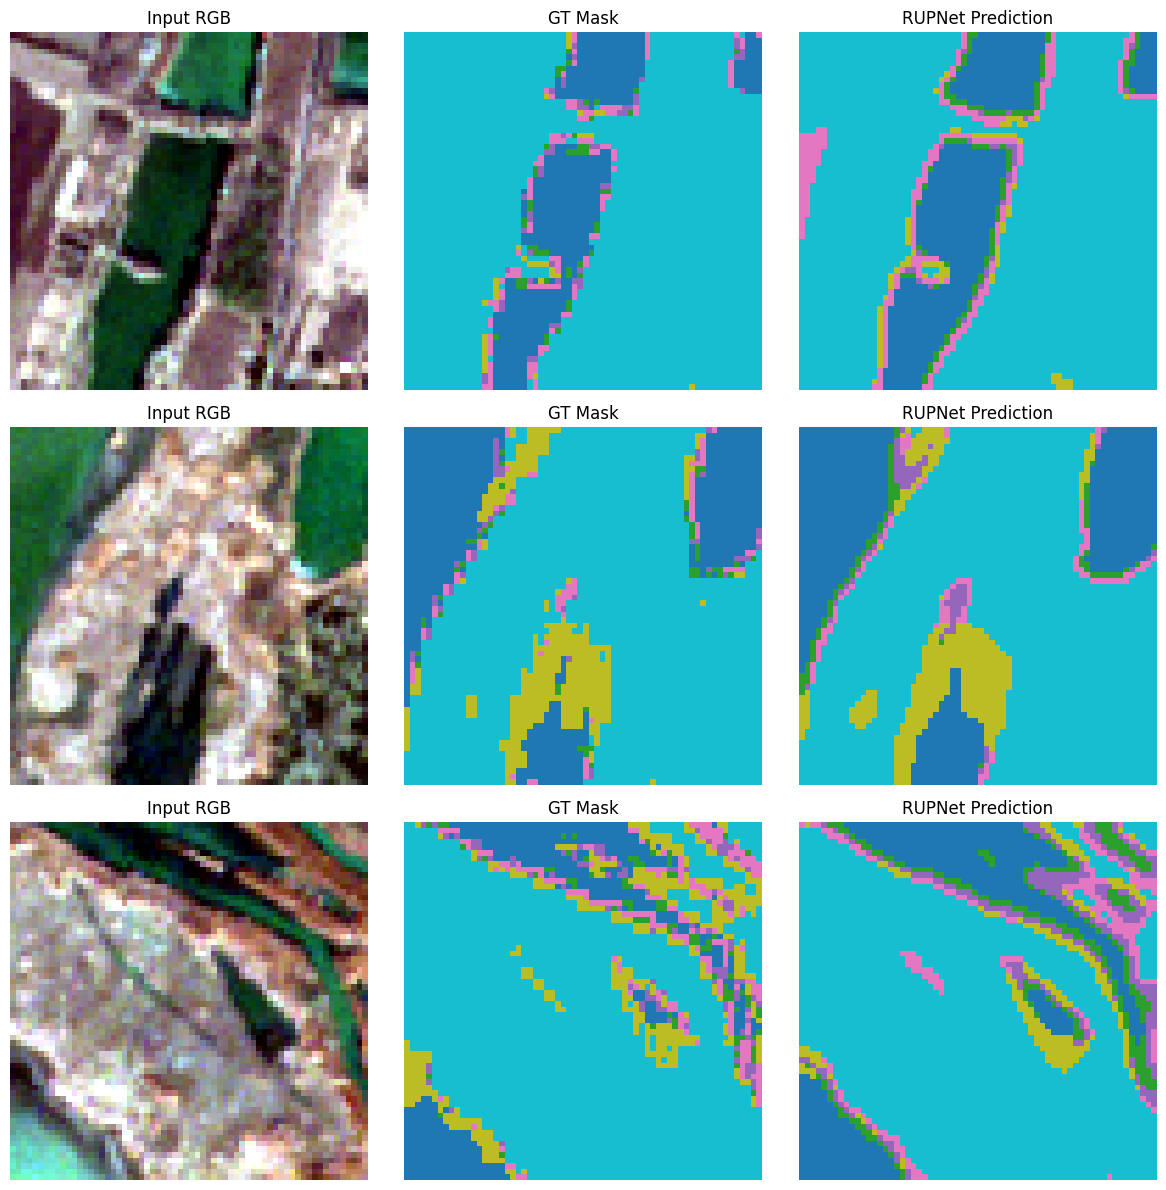

In [ ]:
# Pick patches by GT class diversity instead of arbitrary fixed indices - most patches are
# 80%+ "not affected" (class 5, i.e. raw class 7), so a naive fixed stride mostly lands on
# near-uniform crops that make the model (and the data) look duller than they are. Scanning
# for the most class-diverse patches gives a genuinely informative qualitative comparison.
def patch_class_diversity(idx):
    _, _, gt = eval_dataset[idx]
    gt_np = gt.numpy()
    valid = gt_np[gt_np < 6]
    return len(np.unique(valid)) if valid.size else 0

scan_indices = range(0, len(eval_dataset), 37)  # coarse scan (37 avoids aliasing with the patch grid)
diversity_scores = sorted(
    ((idx, patch_class_diversity(idx)) for idx in scan_indices),
    key=lambda t: t[1], reverse=True,
)
chosen = [idx for idx, _ in diversity_scores[:3]]
print(f"Chosen patches (by GT class diversity): {[(idx, s) for idx, s in diversity_scores[:3]]}")

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i, patch_idx in enumerate(chosen):
    s2, _, gt = eval_dataset[patch_idx]

    s2_in = s2.unsqueeze(0).to(device)
    with torch.no_grad():
        logits = model(s2_in)
        pred = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()

    s2_np = s2.numpy()
    rgb = np.stack([s2_np[3], s2_np[2], s2_np[1]], axis=-1)
    rgb = rgb * S2_STD[[3, 2, 1]] + S2_MEAN[[3, 2, 1]]  # undo standardization -> reflectance
    rgb = stretch_rgb(rgb)

    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title("Input RGB")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(gt.numpy(), cmap="tab10", vmin=0, vmax=5)
    axes[i, 1].set_title("GT Mask")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(pred, cmap="tab10", vmin=0, vmax=5)
    axes[i, 2].set_title(f"{MODEL_NAME} Prediction")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()
